# Chapter 16: Regression to Explain Data

Companion notebook for *Master Exploratory Data Analysis: A Hands-On Beginner's Guide with Python, Statistics & A/B Testing*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files are in the same folder as this notebook.

## 16.1 From a Correlation to a Line

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

plt.style.use('book.mplstyle')


def p_text(p):
    return 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'


customers = pd.read_csv('customers.csv', parse_dates=['signup_date'])
orders = pd.read_csv('orders.csv', parse_dates=['order_date'])
cancellations = pd.read_csv('cancellations.csv',
                            parse_dates=['cancel_date'])

customers = customers.merge(
    cancellations[['customer_id', 'cancel_date']],
    on='customer_id', how='left', validate='one_to_one')
data_end = pd.Timestamp('2025-12-31')
customers['end_date'] = customers['cancel_date'].fillna(data_end)
days = (customers['end_date'] - customers['signup_date']).dt.days
customers['tenure_months'] = (days / 30.44).round(1)
customers[['signup_date', 'cancel_date', 'tenure_months']].head(3)

,signup_date,cancel_date,tenure_months
0,2024-01-01,NaT,24.0
1,2024-01-01,2024-01-08,0.2
2,2024-01-01,2025-04-26,15.8


In [2]:
spend = orders.groupby('customer_id')['amount'].sum()
customers['total_spend'] = customers['customer_id'].map(spend)
customers[['tenure_months', 'total_spend', 'age']].describe().round(1)

,tenure_months,total_spend,age
count,4210.0,4210.0,4043.0
mean,5.3,184.1,38.0
std,5.2,227.1,10.8
min,0.0,8.0,18.0
25%,1.2,24.6,30.0
50%,3.4,95.4,38.0
75%,7.9,249.6,45.0
max,24.0,1527.2,76.0


### `smf.ols()`

In [3]:
line_model = smf.ols('total_spend ~ tenure_months',
                     data=customers).fit()
line_model.params.round(2)

Intercept       -17.21
tenure_months    38.16
dtype: float64

### How the line is found

In [4]:
check = customers[['tenure_months', 'total_spend']].copy()
check['fitted'] = line_model.fittedvalues
check['residual'] = line_model.resid
check.head(3).round(2)

,tenure_months,total_spend,fitted,residual
0,24.0,435.37,898.70,-463.33
1,0.2,8.00,-9.58,17.58
2,15.8,479.02,585.76,-106.74


In [5]:
best = (line_model.resid ** 2).sum()
other_line = -17.21 + 40 * customers['tenure_months']
other = ((customers['total_spend'] - other_line) ** 2).sum()
print(f'Fitted line: {best / 1e6:.2f} million')
print(f'Slope of 40: {other / 1e6:.2f} million')

Fitted line: 49.66 million
Slope of 40: 50.44 million


### R² for one predictor

In [6]:
r = customers['tenure_months'].corr(customers['total_spend'])
print(f'r = {r:.3f}, r squared = {r ** 2:.3f}')
print(f'R² = {line_model.rsquared:.3f}')

r = 0.878, r squared = 0.771
R² = 0.771


## 16.2 Adding More Factors

In [7]:
spend_model = smf.ols('total_spend ~ tenure_months + C(plan) + age',
                      data=customers).fit()
spend_model.params.round(2)

Intercept              -69.37
C(plan)[T.Premium]     202.74
C(plan)[T.Standard]     37.40
tenure_months           34.86
age                      0.44
dtype: float64

### Holding the others steady

In [8]:
by_plan = customers.groupby('plan')[['tenure_months', 'total_spend']]
by_plan.mean().round(2)

,tenure_months,total_spend
plan,,
Basic,3.73,77.72
Premium,7.18,401.09
Standard,6.18,200.34


### Categories and the baseline

In [9]:
premium_base = smf.ols(
    "total_spend ~ tenure_months + C(plan, Treatment('Premium'))"
    " + age", data=customers).fit()
premium_base.params.round(2)

Intercept                                    133.37
C(plan, Treatment('Premium'))[T.Basic]      -202.74
C(plan, Treatment('Premium'))[T.Standard]   -165.34
tenure_months                                 34.86
age                                            0.44
dtype: float64

### Blank values are dropped

In [10]:
print(f'Customers: {len(customers):,}')
print(f'Rows used: {spend_model.nobs:,.0f}')

Customers: 4,210
Rows used: 4,043


## 16.3 Reading `summary()` Line by Line

### `results.summary()`

In [11]:
report = spend_model.summary(slim=True)
print(report.tables[0])
print(report.tables[1])

                            OLS Regression Results                            
Dep. Variable:            total_spend   R-squared:                       0.876
Model:                            OLS   Adj. R-squared:                  0.876
No. Observations:                4043   F-statistic:                     7121.
Covariance Type:            nonrobust   Prob (F-statistic):               0.00
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept             -69.3688      4.819    -14.394      0.000     -78.818     -59.920
C(plan)[T.Premium]    202.7398      3.529     57.454      0.000     195.821     209.658
C(plan)[T.Standard]    37.3961      2.880     12.983      0.000      31.749      43.043
tenure_months          34.8637      0.251    138.691      0.000      34.371      35.357
age                     0.4434      0.117      3.797      0.000       0.214  

### From the table to a report

In [12]:
for name, p in spend_model.pvalues.items():
    print(f'{name:<20} {p_text(p)}')

Intercept            p < 0.001
C(plan)[T.Premium]   p < 0.001
C(plan)[T.Standard]  p < 0.001
tenure_months        p < 0.001
age                  p < 0.001


In [13]:
spend_ci = spend_model.conf_int()
spend_ci.columns = ['low', 'high']
spend_ci['coef'] = spend_model.params
spend_ci.round(2)

,low,high,coef
Intercept,-78.82,-59.92,-69.37
C(plan)[T.Premium],195.82,209.66,202.74
C(plan)[T.Standard],31.75,43.04,37.40
tenure_months,34.37,35.36,34.86
age,0.21,0.67,0.44


### The bottom table

In [14]:
print(spend_model.summary().tables[2])

Omnibus:                     1566.516   Durbin-Watson:                   2.001
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            23720.194
Skew:                           1.430   Prob(JB):                         0.00
Kurtosis:                      14.516   Cond. No.                         159.


## 16.4 R² and Adjusted R²

### `results.rsquared`

In [15]:
print(f'R²: {spend_model.rsquared:.3f}')
print(f'Spend, standard deviation: '
      f'${customers["total_spend"].std():.2f}')
print(f'Residuals, standard deviation: '
      f'${spend_model.resid.std():.2f}')

R²: 0.876
Spend, standard deviation: $227.11
Residuals, standard deviation: $79.86


### `results.rsquared_adj`

In [16]:
rng = np.random.default_rng(42)
with_noise = customers.assign(
    noise=rng.normal(size=len(customers)))
noise_model = smf.ols(
    'total_spend ~ tenure_months + C(plan) + age + noise',
    data=with_noise).fit()
print(f'R²:          {spend_model.rsquared:.5f} -> '
      f'{noise_model.rsquared:.5f}')
print(f'Adjusted R²: {spend_model.rsquared_adj:.5f} -> '
      f'{noise_model.rsquared_adj:.5f}')

R²:          0.87583 -> 0.87584
Adjusted R²: 0.87571 -> 0.87569


## 16.5 Checking the Residuals

### Residuals against fitted values

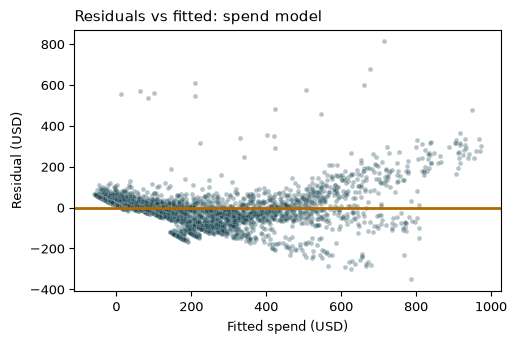

In [17]:
fig, ax = plt.subplots()
sns.scatterplot(x=spend_model.fittedvalues, y=spend_model.resid,
                alpha=0.3, s=12, color='#0b3a47', ax=ax)
ax.axhline(0, color='#b26a00')
ax.set_title('Residuals vs fitted: spend model')
ax.set_xlabel('Fitted spend (USD)')
ax.set_ylabel('Residual (USD)')
plt.show()

In [18]:
resid_check = customers.loc[spend_model.resid.index,
                            ['plan', 'tenure_months']]
resid_check['residual'] = spend_model.resid
long_stay = resid_check[resid_check['tenure_months'] > 12]
long_stay.groupby('plan')['residual'].mean().round(0)

plan
Basic      -190.0
Premium     193.0
Standard    -25.0
Name: residual, dtype: float64

### A Q-Q plot of the residuals

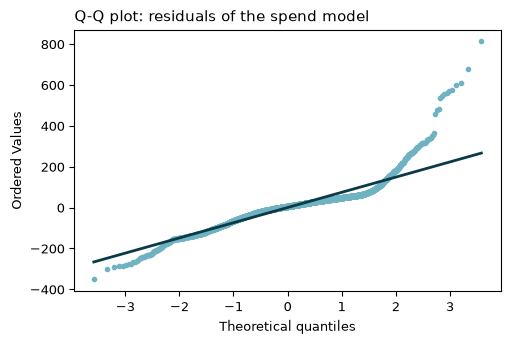

In [19]:
fig, ax = plt.subplots()
stats.probplot(spend_model.resid, plot=ax)
ax.get_lines()[0].set(color='#6fb3c2', markersize=3)
ax.get_lines()[1].set_color('#0b3a47')
ax.set_title('Q-Q plot: residuals of the spend model')
plt.show()

In [20]:
gift_buyers = orders.loc[orders['items'] >= 10, 'customer_id']
resid_check['gift'] = (customers.loc[resid_check.index, 'customer_id']
                       .isin(gift_buyers))
big_miss = resid_check[resid_check['residual'] > 400]
print(f'Residuals above $400: {len(big_miss)}, '
      f'with a gift order: {big_miss["gift"].sum()}')

Residuals above $400: 13, with a gift order: 13


### When the slope differs by group

In [21]:
plan_slopes = smf.ols('total_spend ~ tenure_months * C(plan) + age',
                      data=customers).fit()
plan_slopes.params.round(2)

Intercept                           -14.67
C(plan)[T.Premium]                    0.97
C(plan)[T.Standard]                  -2.92
tenure_months                        19.56
tenure_months:C(plan)[T.Premium]     35.41
tenure_months:C(plan)[T.Standard]    12.53
age                                   0.52
dtype: float64

In [22]:
slope = plan_slopes.params
basic = slope['tenure_months']
pd.Series({
    'Basic': basic,
    'Standard': basic + slope['tenure_months:C(plan)[T.Standard]'],
    'Premium': basic + slope['tenure_months:C(plan)[T.Premium]'],
}, name='dollars per month').round(2)

Basic       19.56
Standard    32.09
Premium     54.96
Name: dollars per month, dtype: float64

In [23]:
print(f'Adjusted R²: {spend_model.rsquared_adj:.3f} -> '
      f'{plan_slopes.rsquared_adj:.3f}')
print(f'Residual std: ${spend_model.resid.std():.2f} -> '
      f'${plan_slopes.resid.std():.2f}')
still_big = plan_slopes.resid > 200
print(f'Residuals above $200: {still_big.sum()}, '
      f'with a gift order: {resid_check.loc[still_big, "gift"].sum()}')

Adjusted R²: 0.876 -> 0.964
Residual std: $79.86 -> $42.94
Residuals above $200: 20, with a gift order: 20


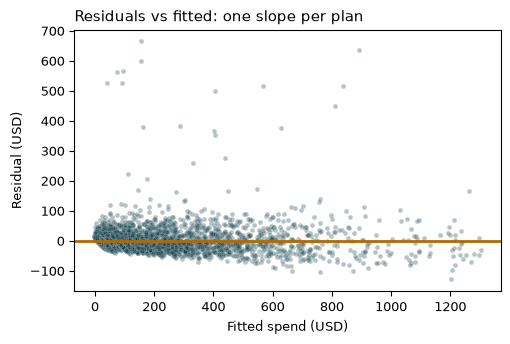

In [24]:
fig, ax = plt.subplots()
sns.scatterplot(x=plan_slopes.fittedvalues, y=plan_slopes.resid,
                alpha=0.3, s=12, color='#0b3a47', ax=ax)
ax.axhline(0, color='#b26a00')
ax.set_title('Residuals vs fitted: one slope per plan')
ax.set_xlabel('Fitted spend (USD)')
ax.set_ylabel('Residual (USD)')
plt.show()

## 16.6 Predicting for New Customers

### `results.predict()`

In [25]:
what_if = pd.DataFrame({'tenure_months': [12, 12, 12],
                        'plan': ['Basic', 'Standard', 'Premium'],
                        'age': [38, 38, 38]})
what_if['predicted'] = plan_slopes.predict(what_if)
what_if.round(2)

,tenure_months,plan,age,predicted
0,12,Basic,38,239.65
1,12,Standard,38,387.15
2,12,Premium,38,665.52


### How sure is a prediction?

In [26]:
ranges = plan_slopes.get_prediction(what_if).summary_frame()
ranges[['mean', 'mean_ci_lower', 'mean_ci_upper',
        'obs_ci_lower', 'obs_ci_upper']].round(0)

,mean,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,240.0,235.0,244.0,155.0,324.0
1,387.0,384.0,390.0,303.0,471.0
2,666.0,662.0,669.0,581.0,750.0


### Beyond the data

In [27]:
far_out = pd.DataFrame({'tenure_months': [24, 60],
                        'plan': ['Premium', 'Premium'],
                        'age': [38, 38]})
far_out['predicted'] = plan_slopes.predict(far_out)
print(f"Longest tenure in the data: "
      f"{customers['tenure_months'].max()} months")
far_out.round(2)

Longest tenure in the data: 24.0 months


,tenure_months,plan,age,predicted
0,24,Premium,38,1325.09
1,60,Premium,38,3303.80


## 16.7 Yes/No Outcomes with Logistic Regression

### Building the columns

In [28]:
boxes = orders[orders['order_type'] == 'Subscription']
first_box = (boxes.sort_values('order_date')
             .groupby('customer_id').first())
customers['first_box_late'] = customers['customer_id'].map(
    first_box['delivery_days'] > 5).astype(int)
customers['first_box_late'].value_counts()

first_box_late
0    3828
1     382
Name: count, dtype: int64

In [29]:
cutoff = data_end - pd.DateOffset(months=4)
early = customers[customers['signup_date'] <= cutoff].copy()
quick_cancel = early['cancel_date'] < (early['signup_date']
                                        + pd.Timedelta(days=90))
early['cancelled_90d'] = quick_cancel.astype(int)
print(f'Signed up by {cutoff:%B %d, %Y}: {len(early):,} customers')
early.groupby('first_box_late')['cancelled_90d'].agg(
    ['mean', 'count']).round(3)

Signed up by August 31, 2025: 3,209 customers


,mean,count
first_box_late,,
0,0.335,2933
1,0.467,276


### Odds

In [30]:
rates = early.groupby('first_box_late')['cancelled_90d'].mean()
odds = rates / (1 - rates)
print(odds.round(3))
print(f'Odds ratio, late vs on time: {odds[1] / odds[0]:.2f}')

first_box_late
0    0.505
1    0.878
Name: cancelled_90d, dtype: float64
Odds ratio, late vs on time: 1.74


### `smf.logit()`

In [31]:
cancel_model = smf.logit(
    'cancelled_90d ~ first_box_late + C(plan) + age',
    data=early).fit(disp=0)
print(cancel_model.summary().tables[1])

                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               0.6529      0.152      4.298      0.000       0.355       0.951
C(plan)[T.Premium]     -1.6324      0.126    -12.994      0.000      -1.879      -1.386
C(plan)[T.Standard]    -0.9624      0.087    -11.025      0.000      -1.134      -0.791
first_box_late          0.6755      0.137      4.941      0.000       0.408       0.943
age                    -0.0202      0.004     -5.400      0.000      -0.028      -0.013


In [32]:
print(f'Rows used: {cancel_model.nobs:,.0f} of {len(early):,}')
print(f'Pseudo R²: {cancel_model.prsquared:.3f}')

Rows used: 3,087 of 3,209
Pseudo R²: 0.075


### Odds ratios with `np.exp()`

In [33]:
odds_ratios = np.exp(cancel_model.conf_int())
odds_ratios.columns = ['low', 'high']
odds_ratios['odds_ratio'] = np.exp(cancel_model.params)
odds_ratios['p'] = cancel_model.pvalues.map(p_text)
odds_ratios.round(2)

,low,high,odds_ratio,p
Intercept,1.43,2.59,1.92,p < 0.001
C(plan)[T.Premium],0.15,0.25,0.20,p < 0.001
C(plan)[T.Standard],0.32,0.45,0.38,p < 0.001
first_box_late,1.50,2.57,1.96,p < 0.001
age,0.97,0.99,0.98,p < 0.001


In [34]:
early.groupby('plan')['first_box_late'].mean().round(3)

plan
Basic       0.080
Premium     0.095
Standard    0.088
Name: first_box_late, dtype: float64

In [35]:
new_customers = pd.DataFrame({'first_box_late': [0, 1, 0, 1],
                              'plan': ['Basic', 'Basic',
                                       'Premium', 'Premium'],
                              'age': [35, 35, 35, 35]})
new_customers['chance'] = cancel_model.predict(new_customers)
new_customers.round(3)

,first_box_late,plan,age,chance
0,0,Basic,35,0.486
1,1,Basic,35,0.650
2,0,Premium,35,0.156
3,1,Premium,35,0.267


## 16.8 What Regression Can't Tell You

### Predictors that move together

In [36]:
order_count = orders.groupby('customer_id').size()
customers['order_count'] = customers['customer_id'].map(order_count)
r_orders = customers['tenure_months'].corr(customers['order_count'])
both = smf.ols(
    'total_spend ~ tenure_months + order_count + C(plan) + age',
    data=customers).fit()
print(f'Tenure vs order count: r = {r_orders:.2f}')
pd.DataFrame({'coef': both.params, 'std err': both.bse,
              'p': both.pvalues.map(p_text)}).round(2)

Tenure vs order count: r = 0.99


,coef,std err,p
Intercept,-63.44,4.33,p < 0.001
C(plan)[T.Premium],183.10,3.23,p < 0.001
C(plan)[T.Standard],38.23,2.59,p < 0.001
tenure_months,-7.84,1.39,p < 0.001
order_count,36.18,1.16,p < 0.001
age,-0.20,0.11,p = 0.057
